# KNN Exercise

![iris](assets/iris.jpg)

We are going to use the famous **iris data set** again. 

The dataset consists of four attributes, which can be used to distinguish different iris species: 
* sepal-width
* sepal-length
* petal-width 
* petal-length. 


The task is to predict the class to which these plants belong. There are three classes in the dataset: **Iris-setosa, Iris-versicolor and Iris-virginica.** 

Further details of the dataset are available [here](https://scikit-learn.org/stable/auto_examples/datasets/plot_iris_dataset.html).

## Task

1. Please import and pre-process the data (as far as it's necessary). Afterwards split it in a train and test set, fit a KNN model and make predictions on the test set. The last step is to evaluate your model. Try to also scale your data and fit the model to the unscaled and scaled data. Can you see a difference in performance? 
If you can't it's because the original features are all on a very similar scale. Try multiplying one of the features by a factor of 10 and fitting the model to unscaled and scaled data. The difference should now be obvious 

2. Please also calculate the accuracy for K values of 1 to 40. In each iteration the accuracy for the predicted values of the test set is calculated and the result is appended to an error list.
The next step is to plot the accuracy values against K values.

Unscaled Accuracy: 1.0
Scaled Accuracy: 1.0
Modified Unscaled Accuracy: 0.9333333333333333
Modified Scaled Accuracy: 1.0


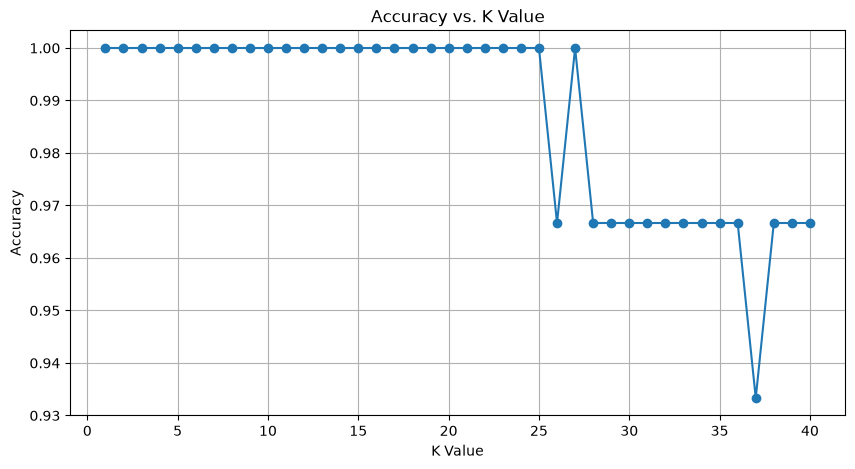

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Veriyi yükleme ve bölme
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Unscaled (Ham) KNN
knn_raw = KNeighborsClassifier(n_neighbors=3)
knn_raw.fit(X_train, y_train)
print("Unscaled Accuracy:", accuracy_score(y_test, knn_raw.predict(X_test)))

# Scaled (Ölçeklendirilmiş) KNN
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

knn_scaled = KNeighborsClassifier(n_neighbors=3)
knn_scaled.fit(X_train_s, y_train)
print("Scaled Accuracy:", accuracy_score(y_test, knn_scaled.predict(X_test_s)))

# Bir özelliği 10 ile çarpma deneyi
X_train_mod = X_train.copy()
X_test_mod = X_test.copy()
X_train_mod[:, 0] *= 10
X_test_mod[:, 0] *= 10

knn_raw.fit(X_train_mod, y_train)
print("Modified Unscaled Accuracy:", accuracy_score(y_test, knn_raw.predict(X_test_mod)))

X_train_mod_s = scaler.fit_transform(X_train_mod)
X_test_mod_s = scaler.transform(X_test_mod)
knn_scaled.fit(X_train_mod_s, y_train)
print("Modified Scaled Accuracy:", accuracy_score(y_test, knn_scaled.predict(X_test_mod_s)))

# 2. k = 1..40 için doğruluk grafiği
accuracies = []
k_values = range(1, 41)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_s, y_train)
    accuracies.append(accuracy_score(y_test, knn.predict(X_test_s)))

plt.figure(figsize=(10, 5))
plt.plot(k_values, accuracies, marker='o')
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. K Value")
plt.grid(True)
plt.show()